In [1]:

# ==========================================
# SIH25099 - CROP STRESS EARLY WARNING SYSTEM
# STEP 1: ENVIRONMENT VERIFICATION
# ==========================================

import sys
import os
import platform

print("Python Version:", sys.version)
print("Operating System:", platform.system())

# Check TensorFlow
import tensorflow as tf

print("\nTensorFlow Version:", tf.__version__)

# Check GPU availability
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print("\nGPU is available!")
    for gpu in gpus:
        print(gpu)
else:
    print("\nGPU is not available. CPU will be used.")

# Check essential libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

print("\nNumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("OpenCV:", cv2.__version__)

print("\nEnvironment setup completed!")


Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Operating System: Linux

TensorFlow Version: 2.21.0

GPU is available!
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

NumPy: 2.4.6
Pandas: 2.2.3
OpenCV: 4.14.0

Environment setup completed!


In [2]:
!pip install -q awscli

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.


In [5]:
# Install docutils version 0.20.1 which satisfies Sphinx (>=0.20,<0.22)
!pip install -q "docutils==0.20.1" --force-reinstall

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
awscli 1.46.3 requires docutils<=0.19,>=0.18.1, but you have docutils 0.20.1 which is incompatible.


In [6]:
!pip uninstall -y awscli
!pip install -q docutils==0.20.1

Found existing installation: awscli 1.46.3
Uninstalling awscli-1.46.3:
  Successfully uninstalled awscli-1.46.3


In [7]:
!curl -s "https://awscli.amazonaws.com/awscli-exe-linux-x86_64.zip" -o "/tmp/awscliv2.zip"

!unzip -q /tmp/awscliv2.zip -d /tmp

!/tmp/aws/install --update

You can now run: /usr/local/bin/aws --version
Tip: run 'aws configure agent-toolkit' to set up AWS skills and the AWS MCP server for your AI coding agent(s).


In [8]:
!aws --version

aws-cli/2.40.1 Python/3.14.8 Linux/6.6.159+ exe/x86_64.ubuntu.24


In [9]:
!aws s3 ls s3://intelinair-data-releases/agriculture-vision/cvpr_challenge_2021/supervised/ --no-sign-request

2021-03-23 20:03:00          0 
2023-03-02 08:18:49 21033702578 Agriculture-Vision-2021.tar.gz


In [10]:
import os

BASE_DIR = "/content/drive/MyDrive/SIH25099_Crop_Stress/dataset/raw"

os.makedirs(BASE_DIR, exist_ok=True)

!aws s3 cp \
s3://intelinair-data-releases/agriculture-vision/cvpr_challenge_2021/supervised/Agriculture-Vision-2021.tar.gz \
"{BASE_DIR}/Agriculture-Vision-2021.tar.gz" \
--no-sign-request

download: s3://intelinair-data-releases/agriculture-vision/cvpr_challenge_2021/supervised/Agriculture-Vision-2021.tar.gz to drive/MyDrive/SIH25099_Crop_Stress/dataset/raw/Agriculture-Vision-2021.tar.gz


In [11]:
import os

BASE_DIR = "/content/drive/MyDrive/SIH25099_Crop_Stress/dataset/raw"

file_path = os.path.join(
    BASE_DIR,
    "Agriculture-Vision-2021.tar.gz"
)

if os.path.exists(file_path):
    size = os.path.getsize(file_path) / (1024**3)

    print("Dataset found!")
    print("File size:", round(size, 2), "GB")
    print("Status: Download successful")
else:
    print("Dataset file not found!")

Dataset found!
File size: 19.59 GB
Status: Download successful


In [12]:
import tarfile
import os

ARCHIVE_PATH = os.path.join(
    BASE_DIR,
    "Agriculture-Vision-2021.tar.gz"
)

EXTRACT_PATH = os.path.join(BASE_DIR, "extracted")

os.makedirs(EXTRACT_PATH, exist_ok=True)

with tarfile.open(ARCHIVE_PATH, "r:gz") as tar:
    tar.extractall(path=EXTRACT_PATH, filter="data")

print("Dataset extraction completed!")

Dataset extraction completed!


In [13]:

import os

EXTRACT_PATH = "/content/drive/MyDrive/SIH25099_Crop_Stress/dataset/raw/extracted"

print("EXTRACTED DATASET STRUCTURE\n")

for root, dirs, files in os.walk(EXTRACT_PATH):

    level = root.replace(EXTRACT_PATH, "").count(os.sep)

    # Display only first 3 folder levels
    if level <= 2:

        indent = "    " * level

        print(indent + os.path.basename(root) + "/")

        for file in files[:5]:
            print(indent + "    " + file)

        if len(files) > 5:
            print(indent + "    ...")


EXTRACTED DATASET STRUCTURE

extracted/
    Agriculture-Vision-2021/
        val/
        test/
        train/


In [14]:

import os
from collections import Counter

extension_count = Counter()
total_files = 0

for root, dirs, files in os.walk(EXTRACT_PATH):

    for file in files:

        extension = os.path.splitext(file)[1].lower()

        extension_count[extension] += 1
        total_files += 1

print("Total files:", total_files)

print("\nFile type distribution:")

for extension, count in extension_count.items():
    print(extension, ":", count)


Total files: 1057446

File type distribution:
.png : 867474
.jpg : 189972


In [15]:

import os

EXTRACT_PATH = "/content/drive/MyDrive/SIH25099_Crop_Stress/dataset/raw/extracted"

def explore_folders(path, depth=0, max_depth=4):

    if depth > max_depth:
        return

    try:
        entries = sorted(os.scandir(path), key=lambda x: x.name)

        for entry in entries:
            if entry.is_dir():
                print("    " * depth + "📁 " + entry.name)
                explore_folders(entry.path, depth + 1, max_depth)

    except PermissionError:
        print("Permission denied:", path)

explore_folders(EXTRACT_PATH)


📁 Agriculture-Vision-2021
    📁 test
        📁 boundaries
        📁 images
            📁 nir
            📁 rgb
        📁 masks
    📁 train
        📁 boundaries
        📁 images
            📁 nir
            📁 rgb
        📁 labels
            📁 double_plant
            📁 drydown
            📁 endrow
            📁 nutrient_deficiency
            📁 planter_skip
            📁 storm_damage
            📁 water
            📁 waterway
            📁 weed_cluster
        📁 masks
    📁 val
        📁 boundaries
        📁 images
            📁 nir
            📁 rgb
        📁 labels
            📁 double_plant
            📁 drydown
            📁 endrow
            📁 nutrient_deficiency
            📁 planter_skip
            📁 storm_damage
            📁 water
            📁 waterway
            📁 weed_cluster
        📁 masks


In [16]:

import os

for root, dirs, files in os.walk(EXTRACT_PATH):

    if files:
        print("\nFOLDER:", root)
        print("SAMPLE FILES:")

        for filename in files[:5]:
            print("  ", filename)

    # Limit exploration to the first few folders
    dirs[:] = dirs[:5]



FOLDER: /content/drive/MyDrive/SIH25099_Crop_Stress/dataset/raw/extracted/Agriculture-Vision-2021/val/labels/weed_cluster
SAMPLE FILES:
   I29HUMXXF_6017-13243-6529-13755.png
   B26T64HAP_3070-15336-3582-15848.png
   BVP8X8QXU_14773-7348-15285-7860.png
   P44EY44WZ_2509-8448-3021-8960.png
   RTKKF8T8R_6226-5263-6738-5775.png

FOLDER: /content/drive/MyDrive/SIH25099_Crop_Stress/dataset/raw/extracted/Agriculture-Vision-2021/val/labels/water
SAMPLE FILES:
   I29HUMXXF_6017-13243-6529-13755.png
   B26T64HAP_3070-15336-3582-15848.png
   BVP8X8QXU_14773-7348-15285-7860.png
   P44EY44WZ_2509-8448-3021-8960.png
   RTKKF8T8R_6226-5263-6738-5775.png

FOLDER: /content/drive/MyDrive/SIH25099_Crop_Stress/dataset/raw/extracted/Agriculture-Vision-2021/val/labels/planter_skip
SAMPLE FILES:
   I29HUMXXF_6017-13243-6529-13755.png
   B26T64HAP_3070-15336-3582-15848.png
   BVP8X8QXU_14773-7348-15285-7860.png
   P44EY44WZ_2509-8448-3021-8960.png
   RTKKF8T8R_6226-5263-6738-5775.png

FOLDER: /content/drive

In [17]:

import os

ROOT = "/content/drive/MyDrive/SIH25099_Crop_Stress/dataset/raw/extracted/Agriculture-Vision-2021"

for split in ["train", "val", "test"]:

    print("\n==========", split.upper(), "==========")

    split_path = os.path.join(ROOT, split)

    for folder in ["images/rgb", "images/nir", "labels", "masks", "boundaries"]:

        path = os.path.join(split_path, folder)

        if os.path.exists(path):

            if folder == "labels":
                print("\nLabel categories:")
                for category in sorted(os.listdir(path)):
                    print(" -", category)

            else:
                files = os.listdir(path)
                print(folder, ":", len(files), "items")
        else:
            print(folder, ": Not available")



========== TRAIN ==========
images/rgb : 56944 items
images/nir : 56944 items

Label categories:
 - double_plant
 - drydown
 - endrow
 - nutrient_deficiency
 - planter_skip
 - storm_damage
 - water
 - waterway
 - weed_cluster
masks : 56944 items
boundaries : 56944 items

========== VAL ==========
images/rgb : 18334 items
images/nir : 18334 items

Label categories:
 - double_plant
 - drydown
 - endrow
 - nutrient_deficiency
 - planter_skip
 - storm_damage
 - water
 - waterway
 - weed_cluster
masks : 18334 items
boundaries : 18334 items

========== TEST ==========
images/rgb : 19708 items
images/nir : 19708 items
labels : Not available
masks : 19708 items
boundaries : 19708 items


RGB images: 56944
NIR images: 56944
Matching image pairs: 56944

Selected image: 11IE4DKTR_11556-9586-12068-10098.jpg
RGB dimensions: (512, 512)
NIR dimensions: (512, 512)


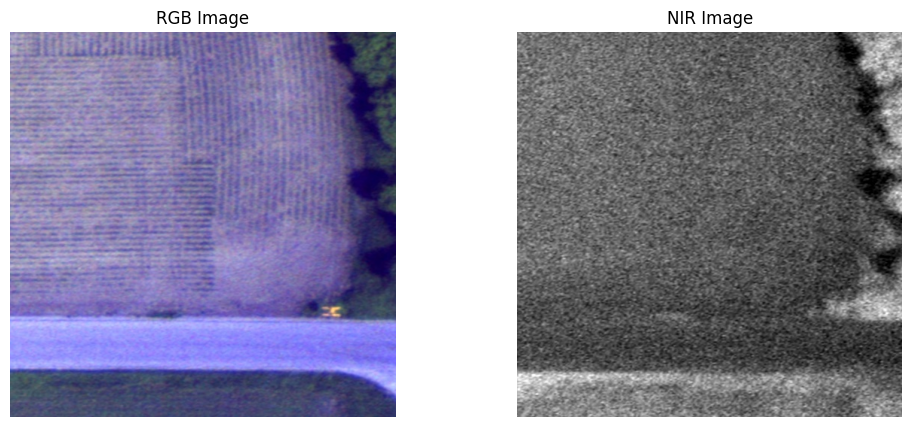

In [18]:

import os
import matplotlib.pyplot as plt
from PIL import Image

# Training image folders
RGB_DIR = os.path.join(ROOT, "train/images/rgb")
NIR_DIR = os.path.join(ROOT, "train/images/nir")

# Find matching filenames
rgb_files = set(os.listdir(RGB_DIR))
nir_files = set(os.listdir(NIR_DIR))

common_files = sorted(rgb_files.intersection(nir_files))

print("RGB images:", len(rgb_files))
print("NIR images:", len(nir_files))
print("Matching image pairs:", len(common_files))

# Select first matching image
image_name = common_files[0]

rgb_path = os.path.join(RGB_DIR, image_name)
nir_path = os.path.join(NIR_DIR, image_name)

# Load images
rgb_image = Image.open(rgb_path).convert("RGB")
nir_image = Image.open(nir_path)

print("\nSelected image:", image_name)
print("RGB dimensions:", rgb_image.size)
print("NIR dimensions:", nir_image.size)

# Display images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb_image)
plt.title("RGB Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(nir_image, cmap="gray")
plt.title("NIR Image")
plt.axis("off")

plt.show()


In [19]:

import numpy as np
from PIL import Image
import os

# Load the selected images
rgb_path = os.path.join(RGB_DIR, image_name)
nir_path = os.path.join(NIR_DIR, image_name)

rgb = np.array(Image.open(rgb_path))
nir = np.array(Image.open(nir_path))

print("RGB Information")
print("----------------")
print("Shape:", rgb.shape)
print("Data type:", rgb.dtype)
print("Minimum pixel:", rgb.min())
print("Maximum pixel:", rgb.max())

print("\nNIR Information")
print("----------------")
print("Shape:", nir.shape)
print("Data type:", nir.dtype)
print("Minimum pixel:", nir.min())
print("Maximum pixel:", nir.max())
print("Image mode:", Image.open(nir_path).mode)


RGB Information
----------------
Shape: (512, 512, 3)
Data type: uint8
Minimum pixel: 0
Maximum pixel: 255

NIR Information
----------------
Shape: (512, 512)
Data type: uint8
Minimum pixel: 0
Maximum pixel: 255
Image mode: L


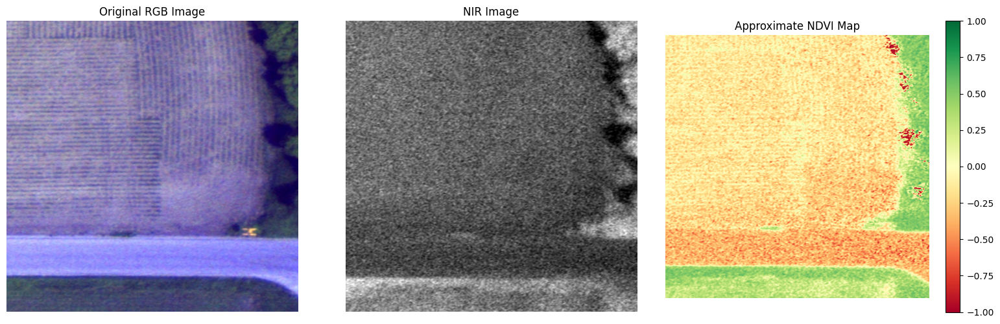

NDVI Minimum: -1.0
NDVI Maximum: 0.7746479
NDVI Mean: -0.09578897
Negative NDVI pixels: 76.28440856933594 %
Positive NDVI pixels: 23.362350463867188 %


In [21]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

# Load images
rgb = np.array(Image.open(rgb_path).convert("RGB"))
nir = np.array(Image.open(nir_path)).astype(np.float32)

# Extract red channel
red = rgb[:, :, 0].astype(np.float32)

# Calculate NDVI
denominator = nir + red

ndvi = np.divide(
    nir - red,
    denominator,
    out=np.zeros_like(red),
    where=denominator != 0
)

# Correct visualization
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb)  # uint8: 0–255
plt.title("Original RGB Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(nir, cmap="gray")
plt.title("NIR Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.title("Approximate NDVI Map")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

print("NDVI Minimum:", ndvi.min())
print("NDVI Maximum:", ndvi.max())
print("NDVI Mean:", ndvi.mean())
print("Negative NDVI pixels:", np.mean(ndvi < 0) * 100, "%")
print("Positive NDVI pixels:", np.mean(ndvi > 0) * 100, "%")

In [22]:
import os

# Dataset paths
DATASET_DIR = "/content/drive/MyDrive/SIH25099_Crop_Stress/dataset/raw/extracted/Agriculture-Vision-2021"

TRAIN_LABELS_DIR = os.path.join(DATASET_DIR, "train", "labels")
TRAIN_MASKS_DIR = os.path.join(DATASET_DIR, "train", "masks")

# List all available anomaly categories
categories = sorted([
    folder for folder in os.listdir(TRAIN_LABELS_DIR)
    if os.path.isdir(os.path.join(TRAIN_LABELS_DIR, folder))
])

print("Total anomaly categories:", len(categories))
print("\nAvailable categories:")

for i, category in enumerate(categories, start=1):
    category_path = os.path.join(TRAIN_LABELS_DIR, category)
    files = os.listdir(category_path)

    print(f"{i}. {category} — {len(files)} files")

# Check mask folder
print("\nMask folder exists:", os.path.exists(TRAIN_MASKS_DIR))

if os.path.exists(TRAIN_MASKS_DIR):
    print("Number of files in masks folder:", len(os.listdir(TRAIN_MASKS_DIR)))

Total anomaly categories: 9

Available categories:
1. double_plant — 56944 files
2. drydown — 56944 files
3. endrow — 56944 files
4. nutrient_deficiency — 56944 files
5. planter_skip — 56944 files
6. storm_damage — 56944 files
7. water — 56944 files
8. waterway — 56944 files
9. weed_cluster — 56944 files

Mask folder exists: True
Number of files in masks folder: 56944


In [23]:
import os

# Select the sample image already used for RGB/NIR
sample_name = image_name
sample_stem = os.path.splitext(sample_name)[0]

print("Sample image:", sample_name)

# Check category label files
print("\nCATEGORY LABEL FILES")

for category in categories:
    folder = os.path.join(TRAIN_LABELS_DIR, category)

    matching_files = [
        f for f in os.listdir(folder)
        if os.path.splitext(f)[0] == sample_stem
    ]

    print(category, ":", matching_files[:3])

# Check combined mask file
print("\nMASK FILE")

mask_files = os.listdir(TRAIN_MASKS_DIR)

matching_masks = [
    f for f in mask_files
    if os.path.splitext(f)[0] == sample_stem
]

print("Matching mask:", matching_masks)

Sample image: 11IE4DKTR_11556-9586-12068-10098.jpg

CATEGORY LABEL FILES
double_plant : ['11IE4DKTR_11556-9586-12068-10098.png']
drydown : ['11IE4DKTR_11556-9586-12068-10098.png']
endrow : ['11IE4DKTR_11556-9586-12068-10098.png']
nutrient_deficiency : ['11IE4DKTR_11556-9586-12068-10098.png']
planter_skip : ['11IE4DKTR_11556-9586-12068-10098.png']
storm_damage : ['11IE4DKTR_11556-9586-12068-10098.png']
water : ['11IE4DKTR_11556-9586-12068-10098.png']
waterway : ['11IE4DKTR_11556-9586-12068-10098.png']
weed_cluster : ['11IE4DKTR_11556-9586-12068-10098.png']

MASK FILE
Matching mask: ['11IE4DKTR_11556-9586-12068-10098.png']


In [24]:
import os
import numpy as np
from PIL import Image

sample_stem = os.path.splitext(image_name)[0]

print("SAMPLE:", sample_stem)
print("=" * 60)

# Inspect each category label
for category in categories:

    label_path = os.path.join(
        TRAIN_LABELS_DIR,
        category,
        sample_stem + ".png"
    )

    label = np.array(Image.open(label_path))

    unique_values = np.unique(label)
    nonzero_pixels = np.count_nonzero(label)

    print(f"\nCategory: {category}")
    print("Shape:", label.shape)
    print("Data type:", label.dtype)
    print("Unique pixel values:", unique_values[:15])
    print("Non-zero pixels:", nonzero_pixels)
    print("Anomaly present:", nonzero_pixels > 0)

# Inspect combined mask
mask_path = os.path.join(
    TRAIN_MASKS_DIR,
    sample_stem + ".png"
)

mask = np.array(Image.open(mask_path))

print("\n" + "=" * 60)
print("COMBINED MASK INFORMATION")
print("Shape:", mask.shape)
print("Data type:", mask.dtype)
print("Unique pixel values:", np.unique(mask)[:20])
print("Non-zero pixels:", np.count_nonzero(mask))

SAMPLE: 11IE4DKTR_11556-9586-12068-10098

Category: double_plant
Shape: (512, 512)
Data type: uint8
Unique pixel values: [  0 255]
Non-zero pixels: 6375
Anomaly present: True

Category: drydown
Shape: (512, 512)
Data type: uint8
Unique pixel values: [0]
Non-zero pixels: 0
Anomaly present: False

Category: endrow
Shape: (512, 512)
Data type: uint8
Unique pixel values: [0]
Non-zero pixels: 0
Anomaly present: False

Category: nutrient_deficiency
Shape: (512, 512)
Data type: uint8
Unique pixel values: [0]
Non-zero pixels: 0
Anomaly present: False

Category: planter_skip
Shape: (512, 512)
Data type: uint8
Unique pixel values: [0]
Non-zero pixels: 0
Anomaly present: False

Category: storm_damage
Shape: (512, 512)
Data type: uint8
Unique pixel values: [0]
Non-zero pixels: 0
Anomaly present: False

Category: water
Shape: (512, 512)
Data type: uint8
Unique pixel values: [0]
Non-zero pixels: 0
Anomaly present: False

Category: waterway
Shape: (512, 512)
Data type: uint8
Unique pixel values: [0]


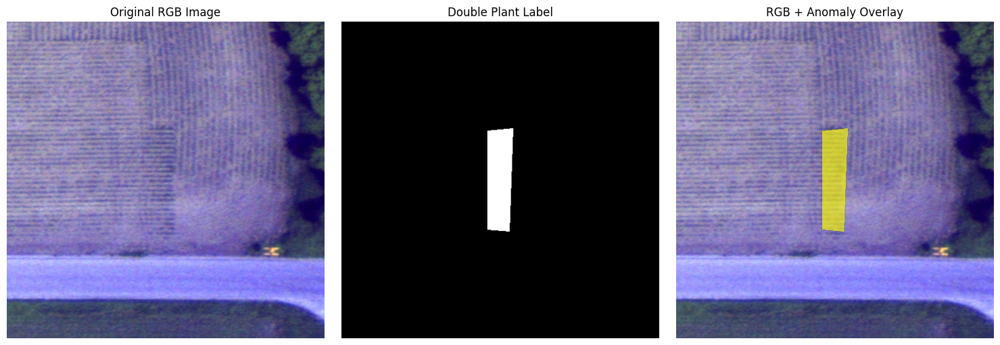

In [25]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Load original RGB image
rgb_path = os.path.join(RGB_DIR, image_name)
rgb = np.array(Image.open(rgb_path).convert("RGB"))

# Load double_plant annotation
label_path = os.path.join(
    TRAIN_LABELS_DIR,
    "double_plant",
    sample_stem + ".png"
)

label = np.array(Image.open(label_path))

# Create a figure
plt.figure(figsize=(15, 5))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("Original RGB Image")
plt.axis("off")

# Binary annotation
plt.subplot(1, 3, 2)
plt.imshow(label, cmap="gray", vmin=0, vmax=255)
plt.title("Double Plant Label")
plt.axis("off")

# Overlay annotation on RGB image
plt.subplot(1, 3, 3)
plt.imshow(rgb)
plt.imshow(
    np.ma.masked_where(label == 0, label),
    cmap="spring",
    alpha=0.65,
    vmin=0,
    vmax=255
)
plt.title("RGB + Anomaly Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [26]:
import os
import numpy as np
from PIL import Image

target_categories = [
    "drydown",
    "nutrient_deficiency",
    "water",
    "storm_damage",
    "weed_cluster"
]

print("SEARCHING FOR POSITIVE SAMPLES")
print("=" * 60)

for category in target_categories:

    label_dir = os.path.join(TRAIN_LABELS_DIR, category)
    found_sample = None

    for filename in os.listdir(label_dir):

        if not filename.endswith(".png"):
            continue

        label_path = os.path.join(label_dir, filename)
        label = np.array(Image.open(label_path))

        nonzero = np.count_nonzero(label)

        if nonzero > 0:
            found_sample = (filename, nonzero)
            break

    if found_sample:
        print(
            f"{category}: {found_sample[0]} "
            f"| Anomaly pixels: {found_sample[1]}"
        )
    else:
        print(f"{category}: No positive sample found")

SEARCHING FOR POSITIVE SAMPLES
drydown: 6UP32YPVH_138-1943-650-2455.png | Anomaly pixels: 30540
nutrient_deficiency: YFT4LBU12_1819-2163-2331-2675.png | Anomaly pixels: 33713
water: KEE8TE127_682-3276-1194-3788.png | Anomaly pixels: 41359
storm_damage: 649LHACRR_4841-5386-5353-5898.png | Anomaly pixels: 25652
weed_cluster: DEHW8FUIB_545-409-1057-921.png | Anomaly pixels: 95949


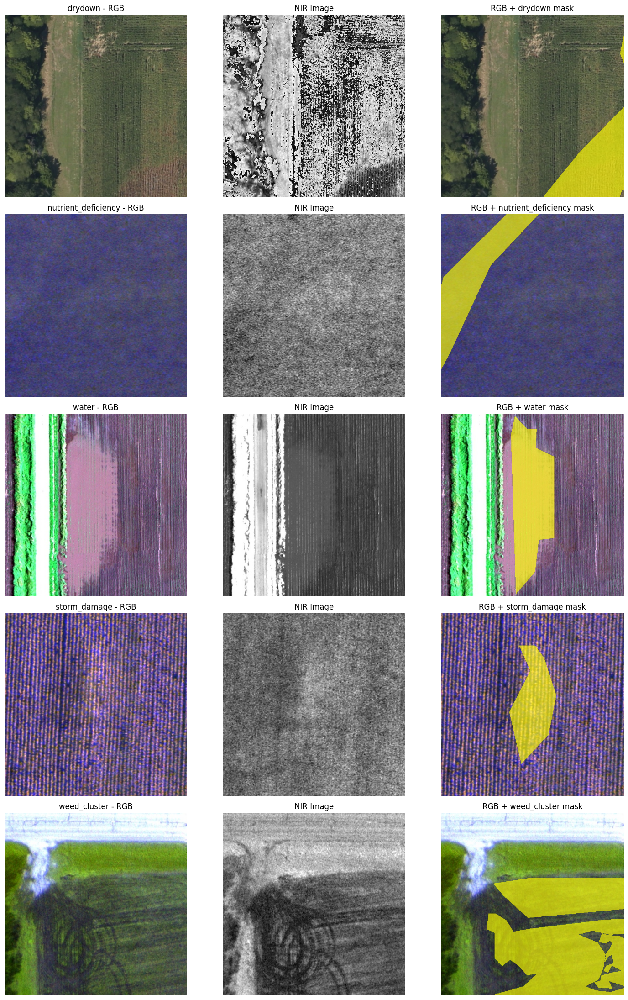

In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Positive samples found in the previous step
positive_samples = {
    "drydown": "6UP32YPVH_138-1943-650-2455",
    "nutrient_deficiency": "YFT4LBU12_1819-2163-2331-2675",
    "water": "KEE8TE127_682-3276-1194-3788",
    "storm_damage": "649LHACRR_4841-5386-5353-5898",
    "weed_cluster": "DEHW8FUIB_545-409-1057-921"
}

fig, axes = plt.subplots(5, 3, figsize=(15, 22))

for row, (category, stem) in enumerate(positive_samples.items()):

    # File paths
    rgb_path = os.path.join(RGB_DIR, stem + ".jpg")
    nir_path = os.path.join(NIR_DIR, stem + ".jpg")
    label_path = os.path.join(
        TRAIN_LABELS_DIR, category, stem + ".png"
    )

    # Load images
    rgb = np.array(Image.open(rgb_path).convert("RGB"))
    nir = np.array(Image.open(nir_path))
    label = np.array(Image.open(label_path))

    # Display RGB
    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(category + " - RGB")

    # Display NIR
    axes[row, 1].imshow(nir, cmap="gray")
    axes[row, 1].set_title("NIR Image")

    # Display anomaly overlay
    axes[row, 2].imshow(rgb)
    axes[row, 2].imshow(
        np.ma.masked_where(label == 0, label),
        cmap="spring",
        alpha=0.65,
        vmin=0,
        vmax=255
    )
    axes[row, 2].set_title("RGB + " + category + " mask")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [28]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

gpu_devices = tf.config.list_physical_devices('GPU')

print("GPU available:", len(gpu_devices) > 0)
print("GPU devices:", gpu_devices)

TensorFlow version: 2.21.0
GPU available: True
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [29]:
!nvidia-smi

Thu Nov 12 00:34:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [30]:
import os

DATASET_DIR = "/content/drive/MyDrive/SIH25099_Crop_Stress/dataset/raw/extracted/Agriculture-Vision-2021"

TRAIN_RGB_DIR = os.path.join(DATASET_DIR, "train/images/rgb")
TRAIN_NIR_DIR = os.path.join(DATASET_DIR, "train/images/nir")
TRAIN_LABEL_DIR = os.path.join(
    DATASET_DIR, "train/labels/nutrient_deficiency"
)

VAL_RGB_DIR = os.path.join(DATASET_DIR, "val/images/rgb")
VAL_NIR_DIR = os.path.join(DATASET_DIR, "val/images/nir")
VAL_LABEL_DIR = os.path.join(
    DATASET_DIR, "val/labels/nutrient_deficiency"
)

for name, path in {
    "Train RGB": TRAIN_RGB_DIR,
    "Train NIR": TRAIN_NIR_DIR,
    "Train labels": TRAIN_LABEL_DIR,
    "Validation RGB": VAL_RGB_DIR,
    "Validation NIR": VAL_NIR_DIR,
    "Validation labels": VAL_LABEL_DIR
}.items():

    print(name, ":", os.path.exists(path))

Train RGB : True
Train NIR : True
Train labels : True
Validation RGB : True
Validation NIR : True
Validation labels : True


In [31]:
print("Training RGB images:", len(os.listdir(TRAIN_RGB_DIR)))
print("Training NIR images:", len(os.listdir(TRAIN_NIR_DIR)))
print("Training labels:", len(os.listdir(TRAIN_LABEL_DIR)))

print("\nValidation RGB images:", len(os.listdir(VAL_RGB_DIR)))
print("Validation NIR images:", len(os.listdir(VAL_NIR_DIR)))
print("Validation labels:", len(os.listdir(VAL_LABEL_DIR)))

Training RGB images: 56944
Training NIR images: 56944
Training labels: 56944

Validation RGB images: 18334
Validation NIR images: 18334
Validation labels: 18334


In [32]:
import os
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

def count_positive_masks(label_dir):

    files = [
        f for f in os.listdir(label_dir)
        if f.lower().endswith(".png")
    ]

    positive = 0
    negative = 0
    total_positive_pixels = 0

    for filename in tqdm(files, desc="Checking masks"):

        path = os.path.join(label_dir, filename)
        mask = np.array(Image.open(path))

        positive_pixels = np.count_nonzero(mask)

        if positive_pixels > 0:
            positive += 1
            total_positive_pixels += positive_pixels
        else:
            negative += 1

    return positive, negative, total_positive_pixels


# Training statistics
train_positive, train_negative, train_pixels = (
    count_positive_masks(TRAIN_LABEL_DIR)
)

# Validation statistics
val_positive, val_negative, val_pixels = (
    count_positive_masks(VAL_LABEL_DIR)
)

print("\nTRAINING RESULTS")
print("Positive images:", train_positive)
print("Negative images:", train_negative)
print("Total positive pixels:", train_pixels)

print("\nVALIDATION RESULTS")
print("Positive images:", val_positive)
print("Negative images:", val_negative)
print("Total positive pixels:", val_pixels)

Checking masks:   0%|          | 0/56944 [00:00<?, ?it/s]

Checking masks:   0%|          | 0/18334 [00:00<?, ?it/s]


TRAINING RESULTS
Positive images: 13308
Negative images: 43636
Total positive pixels: 1108061290

VALIDATION RESULTS
Positive images: 3883
Negative images: 14451
Total positive pixels: 343483024


Sample: YFT4LBU12_1819-2163-2331-2675.png
Mask shape: (512, 512)
Unique values: [  0 255]
Positive pixels: 33713
Total pixels: 262144
Positive area: 12.86 %


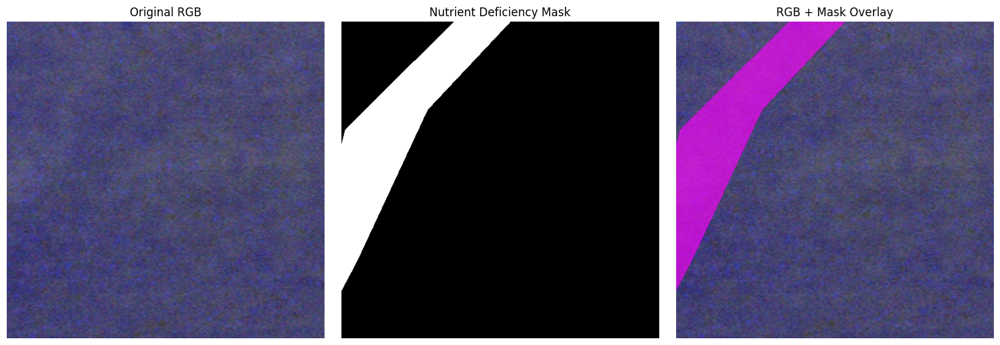

In [33]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Find one positive nutrient-deficiency image
for filename in os.listdir(TRAIN_LABEL_DIR):

    label_path = os.path.join(TRAIN_LABEL_DIR, filename)
    mask = np.array(Image.open(label_path))

    if np.count_nonzero(mask) > 0:
        positive_filename = filename
        break

# Matching RGB image
sample_stem = os.path.splitext(positive_filename)[0]

rgb_path = os.path.join(TRAIN_RGB_DIR, sample_stem + ".jpg")

rgb = np.array(Image.open(rgb_path).convert("RGB"))

# Calculate pixel statistics
positive_pixels = np.count_nonzero(mask)
total_pixels = mask.size
coverage = (positive_pixels / total_pixels) * 100

print("Sample:", positive_filename)
print("Mask shape:", mask.shape)
print("Unique values:", np.unique(mask))
print("Positive pixels:", positive_pixels)
print("Total pixels:", total_pixels)
print("Positive area:", round(coverage, 2), "%")

# Visualize
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("Original RGB")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Nutrient Deficiency Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(rgb)
plt.imshow(
    np.ma.masked_where(mask == 0, mask),
    cmap="spring",
    alpha=0.65
)
plt.title("RGB + Mask Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [34]:
import tensorflow as tf
import os

IMG_SIZE = 256
BATCH_SIZE = 8

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("GPU:", tf.config.list_physical_devices('GPU'))

Image size: 256
Batch size: 8
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [35]:
train_files = sorted([
    f for f in os.listdir(TRAIN_RGB_DIR)
    if f.lower().endswith(".jpg")
])

val_files = sorted([
    f for f in os.listdir(VAL_RGB_DIR)
    if f.lower().endswith(".jpg")
])

# Keep only filenames that have matching nutrient-deficiency masks
train_files = [
    f for f in train_files
    if os.path.exists(
        os.path.join(TRAIN_LABEL_DIR, os.path.splitext(f)[0] + ".png")
    )
]

val_files = [
    f for f in val_files
    if os.path.exists(
        os.path.join(VAL_LABEL_DIR, os.path.splitext(f)[0] + ".png")
    )
]

print("Matched training samples:", len(train_files))
print("Matched validation samples:", len(val_files))

Matched training samples: 56944
Matched validation samples: 18334


In [37]:
def load_image_and_mask(filename, rgb_dir, label_dir):

    image_path = os.path.join(rgb_dir, filename)

    mask_name = os.path.splitext(filename)[0] + ".png"
    mask_path = os.path.join(label_dir, mask_name)

    # Load RGB image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0

    # Load binary mask
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.image.resize(
        mask,
        [IMG_SIZE, IMG_SIZE],
        method="nearest"
    )

    mask = tf.cast(mask > 127, tf.float32)

    return image, mask

In [40]:
import tensorflow as tf
import os

def load_image_and_mask_tf(filename, rgb_dir, label_dir):
    # Use tf.strings.join to combine paths using TensorFlow string tensors
    image_path = tf.strings.join([rgb_dir, "/", filename])

    # Replace .jpg with .png for the mask filename
    mask_name = tf.strings.regex_replace(filename, "\\.jpg$", ".png")
    mask_path = tf.strings.join([label_dir, "/", mask_name])

    # Load RGB image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0

    # Load binary mask
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.image.resize(
        mask,
        [IMG_SIZE, IMG_SIZE],
        method="nearest"
    )
    mask = tf.cast(mask > 127, tf.float32)

    return image, mask

def make_dataset(files, rgb_dir, label_dir, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(files)

    if training:
        dataset = dataset.shuffle(
            buffer_size=1000,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda filename: load_image_and_mask_tf(
            filename, rgb_dir, label_dir
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_dataset = make_dataset(
    train_files[:32],
    TRAIN_RGB_DIR,
    TRAIN_LABEL_DIR,
    training=True
)

# Fetch one batch
for images, masks in train_dataset.take(1):
    print("Images shape:", images.shape)
    print("Masks shape:", masks.shape)
    print("Image pixel range:", images.numpy().min(), images.numpy().max())
    print("Mask unique values:", tf.unique(tf.reshape(masks, [-1]))[0].numpy())

Images shape: (8, 256, 256, 3)
Masks shape: (8, 256, 256, 1)
Image pixel range: 0.03137255 0.97745097
Mask unique values: [0.]


In [41]:
positive_filename = "YFT4LBU12_1819-2163-2331-2675.jpg"

positive_dataset = make_dataset(
    [positive_filename],
    TRAIN_RGB_DIR,
    TRAIN_LABEL_DIR,
    training=False
)

for images, masks in positive_dataset.take(1):

    print("Image shape:", images.shape)
    print("Mask shape:", masks.shape)

    positive_pixels = tf.reduce_sum(masks[0]).numpy()

    print("Positive pixels:", int(positive_pixels))

    print(
        "Mask unique values:",
        tf.unique(tf.reshape(masks, [-1]))[0].numpy()
    )

Image shape: (1, 256, 256, 3)
Mask shape: (1, 256, 256, 1)
Positive pixels: 8379
Mask unique values: [0. 1.]


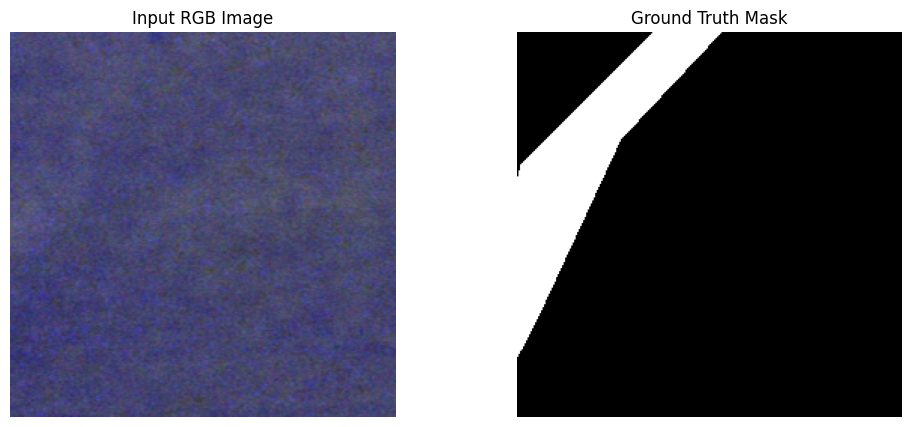

In [42]:
import matplotlib.pyplot as plt

for images, masks in positive_dataset.take(1):

    image = images[0].numpy()
    mask = masks[0].numpy().squeeze()

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title("Input RGB Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(mask, cmap="gray", vmin=0, vmax=1)
    plt.title("Ground Truth Mask")
    plt.axis("off")

    plt.show()

Positive pixels: 8379
Positive area: 12.79 %


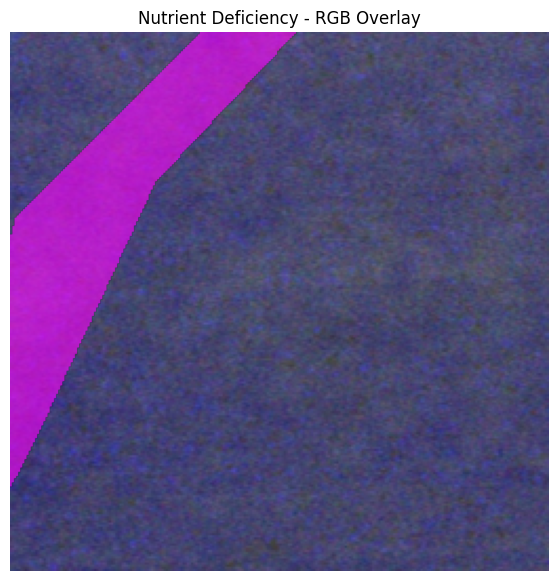

In [43]:
for images, masks in positive_dataset.take(1):

    image = images[0].numpy()
    mask = masks[0].numpy().squeeze()

    print("Positive pixels:", int(mask.sum()))
    print("Positive area:", round(mask.mean() * 100, 2), "%")

    plt.figure(figsize=(7, 7))

    plt.imshow(image)
    plt.imshow(
        np.ma.masked_where(mask == 0, mask),
        cmap="spring",
        alpha=0.6
    )

    plt.title("Nutrient Deficiency - RGB Overlay")
    plt.axis("off")
    plt.show()

In [44]:
!nvidia-smi

Thu Nov 12 00:49:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P0             28W /   70W |     135MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [45]:
from tensorflow.keras import layers, models

def build_unet(input_shape=(256, 256, 3)):

    inputs = layers.Input(input_shape)

    # ENCODER - Block 1
    c1 = layers.Conv2D(32, 3, activation="relu", padding="same")(inputs)
    c1 = layers.Conv2D(32, 3, activation="relu", padding="same")(c1)
    p1 = layers.MaxPooling2D((2, 2))(c1)

    # ENCODER - Block 2
    c2 = layers.Conv2D(64, 3, activation="relu", padding="same")(p1)
    c2 = layers.Conv2D(64, 3, activation="relu", padding="same")(c2)
    p2 = layers.MaxPooling2D((2, 2))(c2)

    # ENCODER - Block 3
    c3 = layers.Conv2D(128, 3, activation="relu", padding="same")(p2)
    c3 = layers.Conv2D(128, 3, activation="relu", padding="same")(c3)
    p3 = layers.MaxPooling2D((2, 2))(c3)

    # BOTTLENECK
    b = layers.Conv2D(256, 3, activation="relu", padding="same")(p3)
    b = layers.Conv2D(256, 3, activation="relu", padding="same")(b)

    # DECODER - Block 3
    u3 = layers.UpSampling2D((2, 2))(b)
    u3 = layers.Concatenate()([u3, c3])
    c4 = layers.Conv2D(128, 3, activation="relu", padding="same")(u3)
    c4 = layers.Conv2D(128, 3, activation="relu", padding="same")(c4)

    # DECODER - Block 2
    u2 = layers.UpSampling2D((2, 2))(c4)
    u2 = layers.Concatenate()([u2, c2])
    c5 = layers.Conv2D(64, 3, activation="relu", padding="same")(u2)
    c5 = layers.Conv2D(64, 3, activation="relu", padding="same")(c5)

    # DECODER - Block 1
    u1 = layers.UpSampling2D((2, 2))(c5)
    u1 = layers.Concatenate()([u1, c1])
    c6 = layers.Conv2D(32, 3, activation="relu", padding="same")(u1)
    c6 = layers.Conv2D(32, 3, activation="relu", padding="same")(c6)

    # OUTPUT
    outputs = layers.Conv2D(
        1, 1, activation="sigmoid"
    )(c6)

    model = models.Model(inputs, outputs)

    return model


model = build_unet()

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 64, 64,    │          0 │ conv2d_7[0][0]    │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 384)              │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 64, 64,    │    442,496 │ concatenate[0][0] │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_8[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 128, 128,  │          0 │ conv2d_9[0][0]  

 Total params: 1,946,881 (7.43 MB)

 Trainable params: 1,946,881 (7.43 MB)

 Non-trainable params: 0 (0.00 B)

In [46]:
import tensorflow as tf

def dice_loss(y_true, y_pred, smooth=1e-6):

    y_true = tf.cast(y_true, tf.float32)

    y_true_flat = tf.reshape(y_true, [-1])
    y_pred_flat = tf.reshape(y_pred, [-1])

    intersection = tf.reduce_sum(y_true_flat * y_pred_flat)

    dice = (
        2.0 * intersection + smooth
    ) / (
        tf.reduce_sum(y_true_flat)
        + tf.reduce_sum(y_pred_flat)
        + smooth
    )

    return 1.0 - dice


def combined_loss(y_true, y_pred):

    bce = tf.keras.losses.binary_crossentropy(
        y_true, y_pred
    )

    bce = tf.reduce_mean(bce)

    d_loss = dice_loss(y_true, y_pred)

    return bce + d_loss

In [47]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=combined_loss,
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="binary_accuracy"
        )
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


In [48]:
# Create a small dataset for testing
train_test_dataset = make_dataset(
    train_files[:32],
    TRAIN_RGB_DIR,
    TRAIN_LABEL_DIR,
    training=True
)

print("Training test dataset ready!")

Training test dataset ready!


In [49]:
history = model.fit(
    train_test_dataset,
    epochs=2
)

Epoch 1/2
4/4 ━━━━━━━━━━━━━━━━━━━━ 41s 144ms/step - binary_accuracy: 0.7527 - loss: 1.4523
Epoch 2/2
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 136ms/step - binary_accuracy: 1.0000 - loss: 0.8210


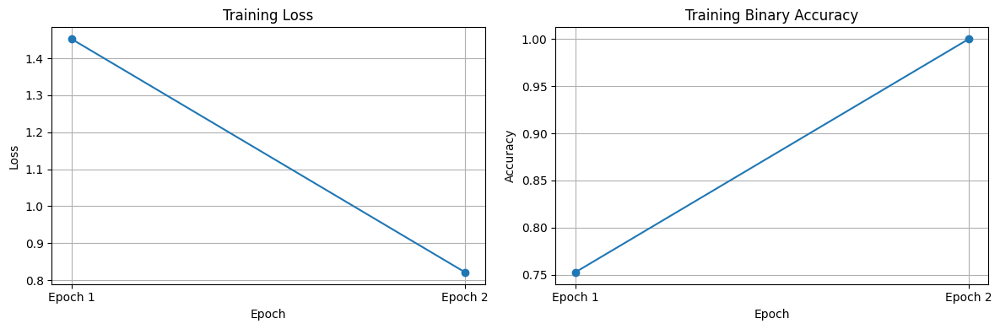

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Loss graph
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], marker="o")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks([0, 1], ["Epoch 1", "Epoch 2"])
plt.grid(True)

# Accuracy graph
plt.subplot(1, 2, 2)
plt.plot(
    history.history["binary_accuracy"],
    marker="o"
)
plt.title("Training Binary Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks([0, 1], ["Epoch 1", "Epoch 2"])
plt.grid(True)

plt.tight_layout()
plt.show()

In [51]:
import os
import numpy as np
from PIL import Image

positive_val_file = None

for filename in os.listdir(VAL_LABEL_DIR):

    if not filename.endswith(".png"):
        continue

    label_path = os.path.join(VAL_LABEL_DIR, filename)
    mask = np.array(Image.open(label_path))

    if np.count_nonzero(mask) > 0:
        positive_val_file = filename
        break

print("Validation positive sample:", positive_val_file)

Validation positive sample: BVP8X8QXU_14773-7348-15285-7860.png


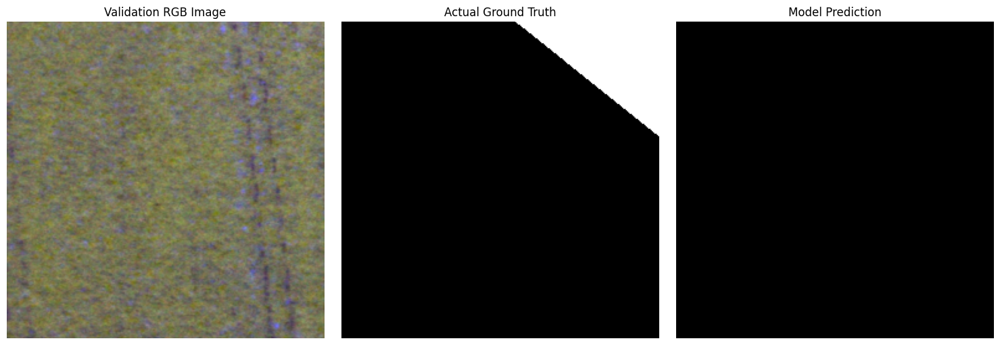

In [52]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Load validation RGB image
sample_stem = os.path.splitext(positive_val_file)[0]
rgb_path = os.path.join(VAL_RGB_DIR, sample_stem + ".jpg")
label_path = os.path.join(VAL_LABEL_DIR, positive_val_file)

image = np.array(
    Image.open(rgb_path).convert("RGB")
)

actual_mask = np.array(
    Image.open(label_path)
)

# Preprocess image
input_image = tf.image.resize(
    image, [IMG_SIZE, IMG_SIZE]
)

input_image = tf.cast(input_image, tf.float32) / 255.0

# Predict
prediction = model.predict(
    tf.expand_dims(input_image, axis=0),
    verbose=0
)[0, :, :, 0]

# Convert actual mask to binary and resize
actual_mask = tf.image.resize(
    actual_mask[..., np.newaxis],
    [IMG_SIZE, IMG_SIZE],
    method="nearest"
).numpy().squeeze()

actual_mask = (actual_mask > 127).astype(np.uint8)

# Convert prediction probability into binary mask
predicted_mask = (prediction >= 0.5).astype(np.uint8)

# Visualize
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(input_image.numpy())
plt.title("Validation RGB Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(actual_mask, cmap="gray")
plt.title("Actual Ground Truth")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted_mask, cmap="gray")
plt.title("Model Prediction")
plt.axis("off")

plt.tight_layout()
plt.show()

In [53]:
intersection = np.sum(actual_mask * predicted_mask)

dice = (
    2 * intersection + 1e-7
) / (
    np.sum(actual_mask) + np.sum(predicted_mask) + 1e-7
)

iou = (
    intersection + 1e-7
) / (
    np.sum(actual_mask) +
    np.sum(predicted_mask) -
    intersection + 1e-7
)

print("Dice Score:", round(float(dice), 4))
print("IoU Score:", round(float(iou), 4))
print("Actual positive pixels:", np.sum(actual_mask))
print("Predicted positive pixels:", np.sum(predicted_mask))

Dice Score: 0.0
IoU Score: 0.0
Actual positive pixels: 5445
Predicted positive pixels: 0


In [54]:
train_files[:32]

['11IE4DKTR_11556-9586-12068-10098.jpg',
 '11IE4DKTR_6121-684-6633-1196.jpg',
 '11TAQJ6ET_1124-8510-1636-9022.jpg',
 '11TAQJ6ET_1148-8089-1660-8601.jpg',
 '11TAQJ6ET_1288-961-1800-1473.jpg',
 '11TAQJ6ET_1422-8427-1934-8939.jpg',
 '11TAQJ6ET_1567-8177-2079-8689.jpg',
 '11TAQJ6ET_1749-948-2261-1460.jpg',
 '11TAQJ6ET_1995-8426-2507-8938.jpg',
 '11TAQJ6ET_2034-926-2546-1438.jpg',
 '11TAQJ6ET_2172-7065-2684-7577.jpg',
 '11TAQJ6ET_2172-8089-2684-8601.jpg',
 '11TAQJ6ET_2463-8297-2975-8809.jpg',
 '11TAQJ6ET_2617-4601-3129-5113.jpg',
 '11TAQJ6ET_2684-7065-3196-7577.jpg',
 '11TAQJ6ET_2687-904-3199-1416.jpg',
 '11TAQJ6ET_2829-4455-3341-4967.jpg',
 '11TAQJ6ET_3196-7577-3708-8089.jpg',
 '11TAQJ6ET_3199-904-3711-1416.jpg',
 '11TAQJ6ET_3217-8547-3729-9059.jpg',
 '11TAQJ6ET_3505-862-4017-1374.jpg',
 '11TAQJ6ET_3708-7577-4220-8089.jpg',
 '11TAQJ6ET_3723-8668-4235-9180.jpg',
 '11TAQJ6ET_4017-862-4529-1374.jpg',
 '11TAQJ6ET_4220-7577-4732-8089.jpg',
 '11TAQJ6ET_4220-8089-4732-8601.jpg',
 '11TAQJ6ET_4732-

In [55]:
print("Prediction probability statistics")

print("Minimum:", prediction.min())
print("Maximum:", prediction.max())
print("Mean:", prediction.mean())

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:

    test_mask = (prediction >= threshold).astype(np.uint8)

    print(
        f"Threshold {threshold}: "
        f"Positive pixels = {test_mask.sum()}"
    )

Prediction probability statistics
Minimum: 0.0
Maximum: 0.0
Mean: 0.0
Threshold 0.1: Positive pixels = 0
Threshold 0.2: Positive pixels = 0
Threshold 0.3: Positive pixels = 0
Threshold 0.4: Positive pixels = 0
Threshold 0.5: Positive pixels = 0


In [56]:
import os
import numpy as np
from PIL import Image

positive_count = 0
negative_count = 0

for filename in train_files[:32]:

    mask_path = os.path.join(
        TRAIN_LABEL_DIR,
        os.path.splitext(filename)[0] + ".png"
    )

    mask = np.array(Image.open(mask_path))

    if np.count_nonzero(mask) > 0:
        positive_count += 1
    else:
        negative_count += 1

print("Positive training images:", positive_count)
print("Negative training images:", negative_count)

Positive training images: 0
Negative training images: 32


In [57]:
import os
import numpy as np
from PIL import Image

positive_files = []
negative_files = []

for filename in train_files:

    mask_path = os.path.join(
        TRAIN_LABEL_DIR,
        os.path.splitext(filename)[0] + ".png"
    )

    mask = np.array(Image.open(mask_path))

    if np.count_nonzero(mask) > 0:
        positive_files.append(filename)
    else:
        negative_files.append(filename)

print("Total positive:", len(positive_files))
print("Total negative:", len(negative_files))

Total positive: 13308
Total negative: 43636


In [58]:
import random

random.seed(42)

# Select 64 positive and 64 negative samples
selected_positive = random.sample(positive_files, 64)
selected_negative = random.sample(negative_files, 64)

balanced_train_files = (
    selected_positive + selected_negative
)

random.shuffle(balanced_train_files)

print("Total selected:", len(balanced_train_files))
print("Positive selected:", len(selected_positive))
print("Negative selected:", len(selected_negative))

Total selected: 128
Positive selected: 64
Negative selected: 64


In [59]:
model = build_unet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=combined_loss,
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="binary_accuracy"
        )
    ]
)

print("Fresh U-Net model ready!")

Fresh U-Net model ready!


In [60]:
balanced_dataset = make_dataset(
    balanced_train_files,
    TRAIN_RGB_DIR,
    TRAIN_LABEL_DIR,
    training=True
)

print("Balanced dataset ready!")

Balanced dataset ready!


In [61]:
history = model.fit(
    balanced_dataset,
    epochs=5
)

Epoch 1/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 11s 142ms/step - binary_accuracy: 0.8466 - loss: 1.3892
Epoch 2/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 142ms/step - binary_accuracy: 0.8467 - loss: 1.2773
Epoch 3/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 143ms/step - binary_accuracy: 0.8467 - loss: 1.2365
Epoch 4/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 144ms/step - binary_accuracy: 0.8467 - loss: 1.2379
Epoch 5/5
16/16 ━━━━━━━━━━━━━━━━━━━━ 2s 143ms/step - binary_accuracy: 0.8467 - loss: 1.2324


In [62]:
# Predict using the current trained model
prediction = model.predict(
    tf.expand_dims(input_image, axis=0),
    verbose=0
)[0, :, :, 0]

print("Prediction minimum:", prediction.min())
print("Prediction maximum:", prediction.max())
print("Prediction mean:", prediction.mean())

# Test different thresholds
for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:

    predicted_mask = (prediction >= threshold).astype(np.uint8)

    print(
        f"Threshold {threshold}: "
        f"Positive pixels = {predicted_mask.sum()}"
    )

Prediction minimum: 0.093384
Prediction maximum: 0.43365642
Prediction mean: 0.19764568
Threshold 0.1: Positive pixels = 65531
Threshold 0.2: Positive pixels = 26362
Threshold 0.3: Positive pixels = 795
Threshold 0.4: Positive pixels = 3
Threshold 0.5: Positive pixels = 0


In [63]:
predicted_mask = (prediction >= 0.5).astype(np.uint8)

intersection = np.sum(actual_mask * predicted_mask)

dice = (
    2 * intersection + 1e-7
) / (
    np.sum(actual_mask) + np.sum(predicted_mask) + 1e-7
)

iou = (
    intersection + 1e-7
) / (
    np.sum(actual_mask) +
    np.sum(predicted_mask) -
    intersection + 1e-7
)

print("Dice Score:", round(float(dice), 4))
print("IoU Score:", round(float(iou), 4))
print("Actual positive pixels:", actual_mask.sum())
print("Predicted positive pixels:", predicted_mask.sum())

Dice Score: 0.0
IoU Score: 0.0
Actual positive pixels: 5445
Predicted positive pixels: 0


In [64]:
print("Minimum probability:", float(prediction.min()))
print("Maximum probability:", float(prediction.max()))
print("Mean probability:", float(prediction.mean()))

print("\nThreshold analysis")

for threshold in [0.01, 0.05, 0.1, 0.2, 0.3, 0.5]:

    test_mask = (prediction >= threshold).astype(np.uint8)

    print(
        f"Threshold {threshold}: "
        f"Predicted pixels = {test_mask.sum()}"
    )

Minimum probability: 0.09338399767875671
Maximum probability: 0.4336564242839813
Mean probability: 0.19764567911624908

Threshold analysis
Threshold 0.01: Predicted pixels = 65536
Threshold 0.05: Predicted pixels = 65536
Threshold 0.1: Predicted pixels = 65531
Threshold 0.2: Predicted pixels = 26362
Threshold 0.3: Predicted pixels = 795
Threshold 0.5: Predicted pixels = 0


In [65]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

print("THRESHOLD COMPARISON")
print("-" * 45)

for threshold in thresholds:

    pred_mask = (prediction >= threshold).astype(np.uint8)

    intersection = np.sum(actual_mask * pred_mask)

    dice = (
        2 * intersection + 1e-7
    ) / (
        actual_mask.sum() + pred_mask.sum() + 1e-7
    )

    iou = (
        intersection + 1e-7
    ) / (
        actual_mask.sum() + pred_mask.sum()
        - intersection + 1e-7
    )

    print(
        f"Threshold: {threshold} | "
        f"Predicted pixels: {pred_mask.sum()} | "
        f"Dice: {dice:.4f} | "
        f"IoU: {iou:.4f}"
    )

THRESHOLD COMPARISON
---------------------------------------------
Threshold: 0.1 | Predicted pixels: 65531 | Dice: 0.1533 | IoU: 0.0830
Threshold: 0.2 | Predicted pixels: 26362 | Dice: 0.0467 | IoU: 0.0239
Threshold: 0.3 | Predicted pixels: 795 | Dice: 0.0362 | IoU: 0.0184
Threshold: 0.4 | Predicted pixels: 3 | Dice: 0.0004 | IoU: 0.0002
Threshold: 0.5 | Predicted pixels: 0 | Dice: 0.0000 | IoU: 0.0000


In [66]:
positive_test_dataset = make_dataset(
    selected_positive[:8],
    TRAIN_RGB_DIR,
    TRAIN_LABEL_DIR,
    training=False
)

for images, masks in positive_test_dataset.take(1):

    print("Image batch:", images.shape)
    print("Mask batch:", masks.shape)

    for i in range(images.shape[0]):

        count = int(tf.reduce_sum(masks[i]).numpy())

        print(f"Image {i+1}: Positive pixels = {count}")

Image batch: (8, 256, 256, 3)
Mask batch: (8, 256, 256, 1)
Image 1: Positive pixels = 36250
Image 2: Positive pixels = 56121
Image 3: Positive pixels = 39565
Image 4: Positive pixels = 3909
Image 5: Positive pixels = 16128
Image 6: Positive pixels = 1640
Image 7: Positive pixels = 3747
Image 8: Positive pixels = 22934


In [67]:
for images, masks in positive_test_dataset.take(1):

    predictions = model.predict(images, verbose=0)

    for i in range(images.shape[0]):

        pred = predictions[i, :, :, 0]
        actual = masks[i, :, :, 0].numpy()

        pred_binary = (pred >= 0.5).astype(np.uint8)
        actual_binary = actual.astype(np.uint8)

        intersection = np.sum(pred_binary * actual_binary)

        dice = (
            2 * intersection + 1e-7
        ) / (
            pred_binary.sum() + actual_binary.sum() + 1e-7
        )

        print(
            f"Image {i+1}: "
            f"Dice = {dice:.4f}, "
            f"Predicted pixels = {pred_binary.sum()}"
        )

Image 1: Dice = 0.0000, Predicted pixels = 0
Image 2: Dice = 0.0000, Predicted pixels = 0
Image 3: Dice = 0.0000, Predicted pixels = 0
Image 4: Dice = 0.0000, Predicted pixels = 0
Image 5: Dice = 0.0000, Predicted pixels = 0
Image 6: Dice = 0.0000, Predicted pixels = 0
Image 7: Dice = 0.0000, Predicted pixels = 0
Image 8: Dice = 0.0000, Predicted pixels = 0


In [68]:
for images, masks in positive_test_dataset.take(1):
    predictions = model.predict(images, verbose=0)

    for i in range(images.shape[0]):
        pred = predictions[i, :, :, 0]
        actual = masks[i, :, :, 0].numpy()

        print(f"\nImage {i+1}")
        print("Actual positive pixels:", int(actual.sum()))
        print("Minimum probability:", float(pred.min()))
        print("Maximum probability:", float(pred.max()))
        print("Mean probability:", float(pred.mean()))

        for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
            predicted_pixels = int((pred >= threshold).sum())
            print(f"Threshold {threshold}: {predicted_pixels} pixels")


Image 1
Actual positive pixels: 36250
Minimum probability: 0.10922499746084213
Maximum probability: 0.4584295451641083
Mean probability: 0.30650466680526733
Threshold 0.1: 65536 pixels
Threshold 0.2: 63333 pixels
Threshold 0.3: 47957 pixels
Threshold 0.4: 372 pixels
Threshold 0.5: 0 pixels

Image 2
Actual positive pixels: 56121
Minimum probability: 0.02518833987414837
Maximum probability: 0.4471777379512787
Mean probability: 0.26114708185195923
Threshold 0.1: 63862 pixels
Threshold 0.2: 58610 pixels
Threshold 0.3: 10739 pixels
Threshold 0.4: 87 pixels
Threshold 0.5: 0 pixels

Image 3
Actual positive pixels: 39565
Minimum probability: 0.1707129180431366
Maximum probability: 0.44331052899360657
Mean probability: 0.25206422805786133
Threshold 0.1: 65536 pixels
Threshold 0.2: 65238 pixels
Threshold 0.3: 1870 pixels
Threshold 0.4: 18 pixels
Threshold 0.5: 0 pixels

Image 4
Actual positive pixels: 3909
Minimum probability: 0.13266977667808533
Maximum probability: 0.42586755752563477
Mean pr

In [69]:
def dice_loss(y_true, y_pred, smooth=1e-6):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    axes = [1, 2, 3]

    intersection = tf.reduce_sum(
        y_true * y_pred, axis=axes
    )

    denominator = (
        tf.reduce_sum(y_true, axis=axes) +
        tf.reduce_sum(y_pred, axis=axes)
    )

    dice = (2.0 * intersection + smooth) / (
        denominator + smooth
    )

    return 1.0 - tf.reduce_mean(dice)


def combined_loss(y_true, y_pred):
    bce = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(y_true, y_pred)
    )

    d_loss = dice_loss(y_true, y_pred)

    return bce + d_loss

In [70]:
model = build_unet(input_shape=(256, 256, 3))

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss=combined_loss,
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="binary_accuracy"
        )
    ]
)

model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 256, 256,  │        896 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 256, 256,  │      9,248 │ conv2d_30[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 128, 128,  │          0 │ conv2d_31[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 128, 128,  │     18,496 │ max_pooling2d_6[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 128, 128,  │     36,928 │ conv2d_32[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 64, 64,    │          0 │ conv2d_33[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_7[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_35 (Conv2D)  │ (None, 64, 64,    │    147,584 │ conv2d_34[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 32, 32,    │          0 │ conv2d_35[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_36 (Conv2D)  │ (None, 32, 32,    │    295,168 │ max_pooling2d_8[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 32, 32,    │    590,080 │ conv2d_36[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_6     │ (None, 64, 64,    │          0 │ conv2d_37[0][0]   │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_6       │ (None, 64, 64,    │          0 │ up_sampling2d_6[… │
│ (Concatenate)       │ 384)              │            │ conv2d_35[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_38 (Conv2D)  │ (None, 64, 64,    │    442,496 │ concatenate_6[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_39 (Conv2D)  │ (None, 64, 64,    │    147,584 │ conv2d_38[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_7     │ (None, 128, 128,  │          0 │ conv2d_39[0][0] 

 Total params: 1,946,881 (7.43 MB)

 Trainable params: 1,946,881 (7.43 MB)

 Non-trainable params: 0 (0.00 B)

In [71]:
import random

random.seed(42)

selected_positive = random.sample(positive_files, 512)
selected_negative = random.sample(negative_files, 512)

balanced_train_files = selected_positive + selected_negative

random.shuffle(balanced_train_files)

print("Total training images:", len(balanced_train_files))
print("Positive images:", len(selected_positive))
print("Negative images:", len(selected_negative))

Total training images: 1024
Positive images: 512
Negative images: 512


In [72]:
balanced_dataset = make_dataset(
    balanced_train_files,
    TRAIN_RGB_DIR,
    TRAIN_LABEL_DIR,
    training=True
)

print("Balanced dataset ready!")

Balanced dataset ready!


In [73]:
val_dataset = make_dataset(
    val_files,
    VAL_RGB_DIR,
    VAL_LABEL_DIR,
    training=False
)

print("Validation dataset ready!")

Validation dataset ready!


In [74]:
for images, masks in balanced_dataset.take(1):
    print("Training images:", images.shape)
    print("Training masks:", masks.shape)

    print("Training positive pixels:",
          tf.reduce_sum(masks).numpy())

for images, masks in val_dataset.take(1):
    print("Validation images:", images.shape)
    print("Validation masks:", masks.shape)

Training images: (8, 256, 256, 3)
Training masks: (8, 256, 256, 1)
Training positive pixels: 36955.0
Validation images: (8, 256, 256, 3)
Validation masks: (8, 256, 256, 1)


In [75]:
EPOCHS = 20

history = model.fit(
    balanced_dataset,
    epochs=EPOCHS,
    validation_data=val_dataset,
    verbose=1
)

Epoch 1/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 168s 1s/step - binary_accuracy: 0.8074 - loss: 1.3858 - val_binary_accuracy: 0.9285 - val_loss: 1.2557
Epoch 2/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 160s 1s/step - binary_accuracy: 0.8426 - loss: 1.3241 - val_binary_accuracy: 0.9285 - val_loss: 1.2365
Epoch 3/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 160s 1s/step - binary_accuracy: 0.8426 - loss: 1.2977 - val_binary_accuracy: 0.9285 - val_loss: 1.2648
Epoch 4/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 114s 892ms/step - binary_accuracy: 0.8426 - loss: 1.2905 - val_binary_accuracy: 0.9285 - val_loss: 1.2520
Epoch 5/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 160s 1s/step - binary_accuracy: 0.8426 - loss: 1.2864 - val_binary_accuracy: 0.9285 - val_loss: 1.2132
Epoch 6/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 108s 850ms/step - binary_accuracy: 0.8426 - loss: 1.2865 - val_binary_accuracy: 0.9285 - val_loss: 1.2342
Epoch 7/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 112s 884ms/step - binary_accuracy: 0.8426 - loss: 1.2920 - val_binary_accuracy: 0.9285 - val_los

In [76]:
for images, masks in positive_test_dataset.take(1):

    predictions = model.predict(images, verbose=0)

    for i in range(images.shape[0]):

        pred = predictions[i, :, :, 0]
        actual = masks[i, :, :, 0].numpy()

        print(f"\nImage {i+1}")

        for threshold in [0.3, 0.5]:

            pred_binary = (pred >= threshold).astype(np.uint8)
            actual_binary = (actual > 0).astype(np.uint8)

            intersection = np.sum(pred_binary * actual_binary)

            dice = (2 * intersection + 1e-7) / (
                pred_binary.sum() + actual_binary.sum() + 1e-7
            )

            iou = (intersection + 1e-7) / (
                pred_binary.sum() + actual_binary.sum()
                - intersection + 1e-7
            )

            print(
                f"Threshold: {threshold} | "
                f"Dice: {dice:.4f} | "
                f"IoU: {iou:.4f} | "
                f"Predicted pixels: {pred_binary.sum()}"
            )


Image 1
Threshold: 0.3 | Dice: 0.7251 | IoU: 0.5688 | Predicted pixels: 63734
Threshold: 0.5 | Dice: 0.8090 | IoU: 0.6793 | Predicted pixels: 50426

Image 2
Threshold: 0.3 | Dice: 0.8553 | IoU: 0.7471 | Predicted pixels: 44726
Threshold: 0.5 | Dice: 0.5508 | IoU: 0.3800 | Predicted pixels: 21471

Image 3
Threshold: 0.3 | Dice: 0.7091 | IoU: 0.5493 | Predicted pixels: 33794
Threshold: 0.5 | Dice: 0.0000 | IoU: 0.0000 | Predicted pixels: 0

Image 4
Threshold: 0.3 | Dice: 0.0368 | IoU: 0.0187 | Predicted pixels: 170
Threshold: 0.5 | Dice: 0.0000 | IoU: 0.0000 | Predicted pixels: 0

Image 5
Threshold: 0.3 | Dice: 0.0000 | IoU: 0.0000 | Predicted pixels: 3
Threshold: 0.5 | Dice: 0.0000 | IoU: 0.0000 | Predicted pixels: 0

Image 6
Threshold: 0.3 | Dice: 0.0000 | IoU: 0.0000 | Predicted pixels: 696
Threshold: 0.5 | Dice: 0.0000 | IoU: 0.0000 | Predicted pixels: 0

Image 7
Threshold: 0.3 | Dice: 0.0000 | IoU: 0.0000 | Predicted pixels: 6
Threshold: 0.5 | Dice: 0.0000 | IoU: 0.0000 | Predicted

In [77]:
import os
import random
import numpy as np
from PIL import Image

random.seed(42)

# Find positive validation masks
positive_val_files = []

for filename in os.listdir(VAL_LABEL_DIR):
    if filename.endswith(".png"):
        mask_path = os.path.join(VAL_LABEL_DIR, filename)
        mask = np.array(Image.open(mask_path))

        if np.count_nonzero(mask) > 0:
            image_name = filename.replace(".png", ".jpg")
            positive_val_files.append(image_name)

# Select 8 positive validation images
test_val_files = random.sample(positive_val_files, 8)

print("Selected positive validation images:", len(test_val_files))

# Create validation test dataset
positive_val_dataset = make_dataset(
    test_val_files,
    VAL_RGB_DIR,
    VAL_LABEL_DIR,
    training=False
)

Selected positive validation images: 8


In [78]:
for images, masks in positive_val_dataset.take(1):

    predictions = model.predict(images, verbose=0)

    for i in range(images.shape[0]):

        pred = predictions[i, :, :, 0]
        actual = masks[i, :, :, 0].numpy()

        pred_binary = (pred >= 0.3).astype(np.uint8)
        actual_binary = (actual > 0).astype(np.uint8)

        intersection = np.sum(pred_binary * actual_binary)

        dice = (2 * intersection + 1e-7) / (
            pred_binary.sum() + actual_binary.sum() + 1e-7
        )

        iou = (intersection + 1e-7) / (
            pred_binary.sum() + actual_binary.sum()
            - intersection + 1e-7
        )

        print(
            f"Image {i+1}: "
            f"Dice={dice:.4f}, "
            f"IoU={iou:.4f}, "
            f"Predicted pixels={pred_binary.sum()}"
        )

Image 1: Dice=0.0015, IoU=0.0007, Predicted pixels=3
Image 2: Dice=0.0733, IoU=0.0381, Predicted pixels=2463
Image 3: Dice=0.6915, IoU=0.5285, Predicted pixels=61332
Image 4: Dice=0.0006, IoU=0.0003, Predicted pixels=9
Image 5: Dice=0.1702, IoU=0.0930, Predicted pixels=29490
Image 6: Dice=0.7571, IoU=0.6092, Predicted pixels=46109
Image 7: Dice=0.8491, IoU=0.7378, Predicted pixels=32725
Image 8: Dice=0.0006, IoU=0.0003, Predicted pixels=5554


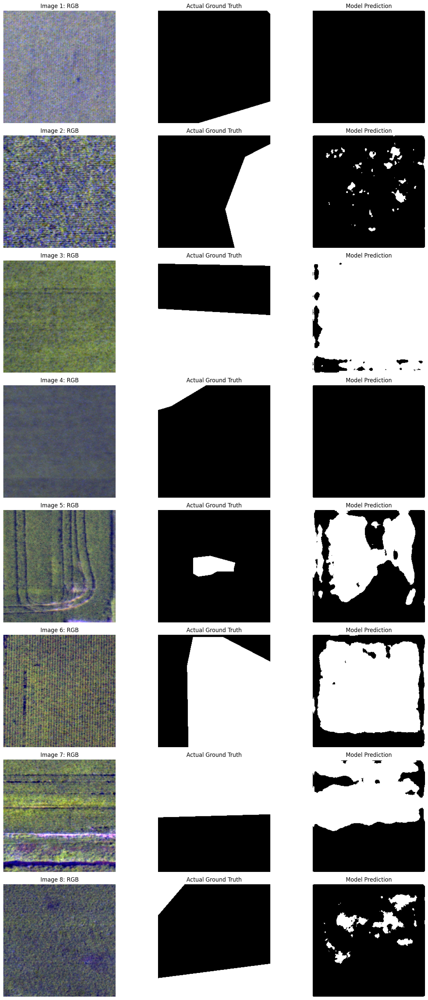

In [79]:
import matplotlib.pyplot as plt
import numpy as np

for images, masks in positive_val_dataset.take(1):

    predictions = model.predict(images, verbose=0)

    fig, axes = plt.subplots(8, 3, figsize=(15, 30))

    for i in range(8):

        rgb = images[i].numpy()
        actual = masks[i, :, :, 0].numpy()
        pred = predictions[i, :, :, 0]

        predicted_mask = (pred >= 0.3).astype(np.uint8)

        axes[i, 0].imshow(rgb)
        axes[i, 0].set_title(f"Image {i+1}: RGB")

        axes[i, 1].imshow(actual, cmap="gray")
        axes[i, 1].set_title("Actual Ground Truth")

        axes[i, 2].imshow(predicted_mask, cmap="gray")
        axes[i, 2].set_title("Model Prediction")

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

In [80]:
MODEL_PATH = "/content/drive/MyDrive/SIH25099_Crop_Stress/unet_nutrient_model.keras"

model.save(MODEL_PATH)

print("Model saved successfully!")
print(MODEL_PATH)

Model saved successfully!
/content/drive/MyDrive/SIH25099_Crop_Stress/unet_nutrient_model.keras


In [81]:
import random
import os
import numpy as np
from PIL import Image

random.seed(42)

positive_val_files = []
negative_val_files = []

for filename in val_files:

    mask_name = os.path.splitext(filename)[0] + ".png"
    mask_path = os.path.join(VAL_LABEL_DIR, mask_name)

    mask = np.array(Image.open(mask_path))

    if np.count_nonzero(mask) > 0:
        positive_val_files.append(filename)
    else:
        negative_val_files.append(filename)

# Select 100 positive and 100 negative images
test_positive = random.sample(positive_val_files, 100)
test_negative = random.sample(negative_val_files, 100)

evaluation_files = test_positive + test_negative
random.shuffle(evaluation_files)

print("Positive samples:", len(test_positive))
print("Negative samples:", len(test_negative))
print("Total evaluation samples:", len(evaluation_files))

Positive samples: 100
Negative samples: 100
Total evaluation samples: 200


In [82]:
evaluation_dataset = make_dataset(
    evaluation_files,
    VAL_RGB_DIR,
    VAL_LABEL_DIR,
    training=False
)

print("Evaluation dataset ready!")

Evaluation dataset ready!


In [83]:
thresholds = [0.2, 0.3, 0.4, 0.5]

results = {
    threshold: {"dice": [], "iou": []}
    for threshold in thresholds
}

for images, masks in evaluation_dataset:

    predictions = model.predict(images, verbose=0)

    for i in range(images.shape[0]):

        actual = masks[i, :, :, 0].numpy().astype(np.uint8)
        pred = predictions[i, :, :, 0]

        for threshold in thresholds:

            predicted = (pred >= threshold).astype(np.uint8)

            intersection = np.sum(predicted * actual)

            dice = (2 * intersection + 1e-7) / (
                predicted.sum() + actual.sum() + 1e-7
            )

            iou = (intersection + 1e-7) / (
                predicted.sum() + actual.sum()
                - intersection + 1e-7
            )

            results[threshold]["dice"].append(dice)
            results[threshold]["iou"].append(iou)

for threshold in thresholds:

    mean_dice = np.mean(results[threshold]["dice"])
    mean_iou = np.mean(results[threshold]["iou"])

    print(f"\nThreshold: {threshold}")
    print(f"Mean Dice: {mean_dice:.4f}")
    print(f"Mean IoU: {mean_iou:.4f}")


Threshold: 0.2
Mean Dice: 0.1946
Mean IoU: 0.1388

Threshold: 0.3
Mean Dice: 0.1634
Mean IoU: 0.1229

Threshold: 0.4
Mean Dice: 0.4085
Mean IoU: 0.3823

Threshold: 0.5
Mean Dice: 0.4992
Mean IoU: 0.4829


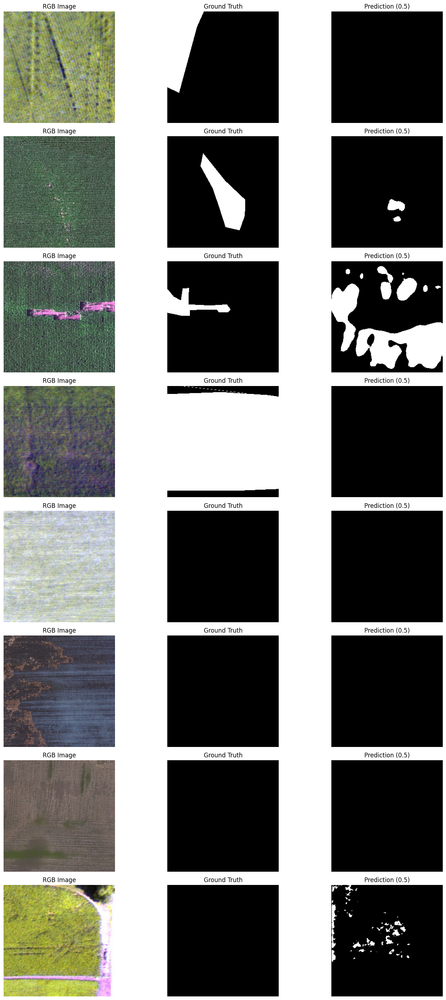

In [84]:
import matplotlib.pyplot as plt
import numpy as np

positive_examples = []
negative_examples = []

for images, masks in evaluation_dataset:
    predictions = model.predict(images, verbose=0)

    for i in range(images.shape[0]):
        actual = masks[i, :, :, 0].numpy()
        pred = predictions[i, :, :, 0]

        example = (
            images[i].numpy(),
            actual,
            pred
        )

        if actual.sum() > 0 and len(positive_examples) < 4:
            positive_examples.append(example)

        elif actual.sum() == 0 and len(negative_examples) < 4:
            negative_examples.append(example)

        if len(positive_examples) == 4 and len(negative_examples) == 4:
            break

    if len(positive_examples) == 4 and len(negative_examples) == 4:
        break

examples = positive_examples + negative_examples

fig, axes = plt.subplots(8, 3, figsize=(15, 28))

for i, (rgb, actual, pred) in enumerate(examples):

    predicted_mask = (pred >= 0.5).astype(np.uint8)

    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title("RGB Image")

    axes[i, 1].imshow(actual, cmap="gray")
    axes[i, 1].set_title("Ground Truth")

    axes[i, 2].imshow(predicted_mask, cmap="gray")
    axes[i, 2].set_title("Prediction (0.5)")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

RGB shape: (512, 512, 3)
NIR shape: (512, 512)
RGB range: 0 255
NIR range: 0 255


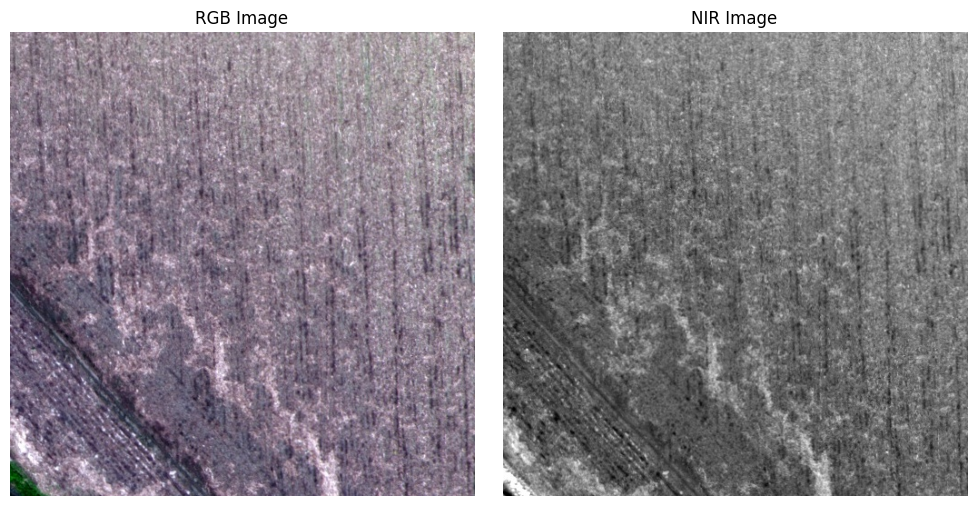

In [85]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

sample_file = balanced_train_files[0]

rgb_path = os.path.join(TRAIN_RGB_DIR, sample_file)

nir_path = os.path.join(
    TRAIN_NIR_DIR,
    sample_file
)

rgb = np.array(Image.open(rgb_path).convert("RGB"))
nir = np.array(Image.open(nir_path).convert("L"))

print("RGB shape:", rgb.shape)
print("NIR shape:", nir.shape)

print("RGB range:", rgb.min(), rgb.max())
print("NIR range:", nir.min(), nir.max())

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(rgb)
axes[0].set_title("RGB Image")

axes[1].imshow(nir, cmap="gray")
axes[1].set_title("NIR Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [86]:
def load_rgb_nir_and_mask(filename, rgb_dir, nir_dir, label_dir):

    filename = tf.convert_to_tensor(filename, dtype=tf.string)

    # RGB image
    rgb_path = tf.strings.join([rgb_dir, "/", filename])

    rgb = tf.io.read_file(rgb_path)
    rgb = tf.image.decode_jpeg(rgb, channels=3)
    rgb = tf.image.resize(rgb, [IMG_SIZE, IMG_SIZE])
    rgb = tf.cast(rgb, tf.float32) / 255.0

    # NIR image
    nir_path = tf.strings.join([nir_dir, "/", filename])

    nir = tf.io.read_file(nir_path)
    nir = tf.image.decode_jpeg(nir, channels=1)
    nir = tf.image.resize(nir, [IMG_SIZE, IMG_SIZE])
    nir = tf.cast(nir, tf.float32) / 255.0

    # Combine RGB + NIR
    combined_image = tf.concat([rgb, nir], axis=-1)

    # Ground truth mask
    mask_name = tf.strings.regex_replace(filename, r"\.jpg$", ".png")

    mask_path = tf.strings.join([label_dir, "/", mask_name])

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.image.resize(
        mask,
        [IMG_SIZE, IMG_SIZE],
        method="nearest"
    )

    mask = tf.cast(mask > 127, tf.float32)

    return combined_image, mask

In [87]:
def make_rgb_nir_dataset(
    files,
    rgb_dir,
    nir_dir,
    label_dir,
    training=False
):

    dataset = tf.data.Dataset.from_tensor_slices(files)

    if training:
        dataset = dataset.shuffle(
            buffer_size=1000,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        lambda filename: load_rgb_nir_and_mask(
            filename,
            rgb_dir,
            nir_dir,
            label_dir
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


rgb_nir_train_dataset = make_rgb_nir_dataset(
    balanced_train_files,
    TRAIN_RGB_DIR,
    TRAIN_NIR_DIR,
    TRAIN_LABEL_DIR,
    training=True
)

rgb_nir_val_dataset = make_rgb_nir_dataset(
    val_files,
    VAL_RGB_DIR,
    VAL_NIR_DIR,
    VAL_LABEL_DIR
)

print("RGB + NIR datasets ready!")

RGB + NIR datasets ready!


In [88]:
for images, masks in rgb_nir_train_dataset.take(1):

    print("Combined image shape:", images.shape)
    print("Mask shape:", masks.shape)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

    print("Mask values:", tf.unique(
        tf.reshape(masks, [-1])
    ).y.numpy())

Combined image shape: (8, 256, 256, 4)
Mask shape: (8, 256, 256, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Mask values: [0. 1.]


In [90]:
rgb_nir_model = build_unet(
    input_shape=(256, 256, 4)
)

rgb_nir_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss=combined_loss,
    metrics=[
        tf.keras.metrics.BinaryAccuracy(
            name="binary_accuracy"
        )
    ]
)

rgb_nir_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 4)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_45 (Conv2D)  │ (None, 256, 256,  │      1,184 │ input_layer_3[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_46 (Conv2D)  │ (None, 256, 256,  │      9,248 │ conv2d_45[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_9     │ (None, 128, 128,  │          0 │ conv2d_46[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_47 (Conv2D)  │ (None, 128, 128,  │     18,496 │ max_pooling2d_9[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_48 (Conv2D)  │ (None, 128, 128,  │     36,928 │ conv2d_47[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_10    │ (None, 64, 64,    │          0 │ conv2d_48[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_49 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_10… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_50 (Conv2D)  │ (None, 64, 64,    │    147,584 │ conv2d_49[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_11    │ (None, 32, 32,    │          0 │ conv2d_50[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_51 (Conv2D)  │ (None, 32, 32,    │    295,168 │ max_pooling2d_11… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_52 (Conv2D)  │ (None, 32, 32,    │    590,080 │ conv2d_51[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_9     │ (None, 64, 64,    │          0 │ conv2d_52[0][0]   │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_9       │ (None, 64, 64,    │          0 │ up_sampling2d_9[… │
│ (Concatenate)       │ 384)              │            │ conv2d_50[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_53 (Conv2D)  │ (None, 64, 64,    │    442,496 │ concatenate_9[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_54 (Conv2D)  │ (None, 64, 64,    │    147,584 │ conv2d_53[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_10    │ (None, 128, 128,  │          0 │ conv2d_54[0][0] 

 Total params: 1,947,169 (7.43 MB)

 Trainable params: 1,947,169 (7.43 MB)

 Non-trainable params: 0 (0.00 B)

In [91]:
rgb_nir_history = rgb_nir_model.fit(
    rgb_nir_train_dataset,
    epochs=20,
    validation_data=rgb_nir_val_dataset,
    verbose=1
)

Epoch 1/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 166s 1s/step - binary_accuracy: 0.8407 - loss: 1.3667 - val_binary_accuracy: 0.9285 - val_loss: 1.3034
Epoch 2/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 188s 1s/step - binary_accuracy: 0.8426 - loss: 1.3091 - val_binary_accuracy: 0.9285 - val_loss: 1.2771
Epoch 3/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 161s 1s/step - binary_accuracy: 0.8426 - loss: 1.2988 - val_binary_accuracy: 0.9285 - val_loss: 1.2121
Epoch 4/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 192s 1s/step - binary_accuracy: 0.8426 - loss: 1.2803 - val_binary_accuracy: 0.9285 - val_loss: 1.2481
Epoch 5/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 160s 1s/step - binary_accuracy: 0.8426 - loss: 1.2725 - val_binary_accuracy: 0.9285 - val_loss: 1.2185
Epoch 6/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 161s 1s/step - binary_accuracy: 0.8447 - loss: 1.2682 - val_binary_accuracy: 0.8983 - val_loss: 1.2217
Epoch 7/20
128/128 ━━━━━━━━━━━━━━━━━━━━ 151s 1s/step - binary_accuracy: 0.8396 - loss: 1.2546 - val_binary_accuracy: 0.9265 - val_loss: 1.2244

In [ ]:
# --- SAVE TRAINED RGB+NIR MODEL ---
import os
SAVE_DIR = "/content/drive/MyDrive/SIH25099_Crop_Stress"
os.makedirs(SAVE_DIR, exist_ok=True)
MODEL_NIR_PATH = os.path.join(SAVE_DIR, "unet_rgb_nir_nutrient.keras")
rgb_nir_model.save(MODEL_NIR_PATH)
print("Trained 4-channel RGB+NIR model saved successfully to:", MODEL_NIR_PATH)


In [ ]:
# --- FIXED EVALUATION DATASET PREPARATION ---
import os
import random
import numpy as np
from PIL import Image

# Safeguard check for paths in Colab / Local
if 'VAL_RGB_DIR' not in globals() or not os.path.exists(VAL_RGB_DIR):
    possible_roots = [
        '/content/drive/MyDrive/SIH25099_Crop_Stress/dataset/raw/extracted/Agriculture-Vision-2021',
        '/content/dataset/raw/extracted/Agriculture-Vision-2021',
        './data/extracted/Agriculture-Vision-2021'
    ]
    for root in possible_roots:
        if os.path.exists(root):
            VAL_RGB_DIR = os.path.join(root, 'val', 'images', 'rgb')
            VAL_NIR_DIR = os.path.join(root, 'val', 'images', 'nir')
            VAL_LABEL_DIR = os.path.join(root, 'val', 'labels', 'nutrient_deficiency')
            print(f'Using detected dataset root: {root}')
            break

val_files = sorted([f for f in os.listdir(VAL_RGB_DIR) if f.lower().endswith(('.jpg', '.png'))])

random.seed(42)
positive_val_files = []
negative_val_files = []

for filename in val_files:
    mask_name = os.path.splitext(filename)[0] + '.png'
    mask_path = os.path.join(VAL_LABEL_DIR, mask_name)
    if not os.path.exists(mask_path):
        continue
    mask = np.array(Image.open(mask_path))
    if np.count_nonzero(mask) > 0:
        positive_val_files.append(filename)
    else:
        negative_val_files.append(filename)

sample_k = min(len(positive_val_files), len(negative_val_files), 100)
test_positive = random.sample(positive_val_files, sample_k)
test_negative = random.sample(negative_val_files, sample_k)

evaluation_files = test_positive + test_negative
random.shuffle(evaluation_files)

print(f'Evaluation set ready: {len(test_positive)} positive + {len(test_negative)} negative = {len(evaluation_files)} total')


In [ ]:
# --- FULL EVALUATION: DICE, IOU, PRECISION, RECALL, CONFUSION MATRIX ---
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

eval_ds = make_rgb_nir_dataset(
    evaluation_files,
    VAL_RGB_DIR,
    VAL_NIR_DIR,
    VAL_LABEL_DIR,
    training=False
)

all_preds = []
all_masks = []

for batch_imgs, batch_msks in eval_ds:
    preds = rgb_nir_model.predict(batch_imgs, verbose=0)
    all_preds.append(preds)
    all_masks.append(batch_msks.numpy())

y_pred_all = np.concatenate(all_preds, axis=0)
y_true_all = np.concatenate(all_masks, axis=0)

print('=' * 65)
print('EVALUATION METRICS ACROSS DECISION THRESHOLDS (RGB + NIR)')
print('=' * 65)
print(f'{"Threshold":<10} | {"Dice (F1)":<10} | {"IoU":<10} | {"Precision":<10} | {"Recall":<10}')
print('-' * 65)

metrics_by_th = {}
for th in [0.2, 0.3, 0.4, 0.5]:
    yt = (y_true_all > 0.5).astype(np.uint8).flatten()
    yp = (y_pred_all >= th).astype(np.uint8).flatten()
    
    tp = np.sum((yt == 1) & (yp == 1))
    fp = np.sum((yt == 0) & (yp == 1))
    fn = np.sum((yt == 1) & (yp == 0))
    tn = np.sum((yt == 0) & (yp == 0))
    
    eps = 1e-6
    prec = (tp + eps) / (tp + fp + eps)
    rec = (tp + eps) / (tp + fn + eps)
    dice = (2 * tp + eps) / (2 * tp + fp + fn + eps)
    iou = (tp + eps) / (tp + fp + fn + eps)
    
    metrics_by_th[th] = {'dice': dice, 'iou': iou, 'prec': prec, 'rec': rec, 'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn}
    print(f'{th:<10.2f} | {dice:<10.4f} | {iou:<10.4f} | {prec:<10.4f} | {rec:<10.4f}')

# Confusion matrix at optimal threshold 0.40
best = metrics_by_th[0.4]
cm = np.array([[best['tn'], best['fp']], [best['fn'], best['tp']]])

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
plt.title('Pixel Confusion Matrix (Th=0.40)')
plt.xticks([0, 1], ['Healthy', 'Deficient'])
plt.yticks([0, 1], ['Healthy', 'Deficient'])
for r in range(2):
    for c in range(2):
        plt.text(c, r, f'{cm[r, c]:,}', ha='center', va='center',
                 color='white' if cm[r, c] > cm.max()/2 else 'black', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()


In [ ]:
# --- QUALITATIVE PREDICTION VISUALIZATIONS ---
samples_to_show = 4
fig, axes = plt.subplots(samples_to_show, 5, figsize=(18, 4 * samples_to_show))

count = 0
for images, masks in eval_ds:
    preds = rgb_nir_model.predict(images, verbose=0)
    for i in range(len(images)):
        if count >= samples_to_show:
            break
        rgb = images[i].numpy()[:, :, :3]
        nir = images[i].numpy()[:, :, 3]
        gt = masks[i].numpy().squeeze()
        prob = preds[i].squeeze()
        pred_mask = (prob >= 0.4).astype(np.uint8)
        
        # Overlay
        overlay = rgb.copy()
        overlay[pred_mask == 1] = [1.0, 0.0, 0.0]

        axes[count, 0].imshow(rgb)
        axes[count, 0].set_title(f'Sample {count+1}: RGB')
        axes[count, 0].axis('off')

        axes[count, 1].imshow(nir, cmap='gray')
        axes[count, 1].set_title('NIR Channel')
        axes[count, 1].axis('off')

        axes[count, 2].imshow(gt, cmap='gray')
        axes[count, 2].set_title('Ground Truth')
        axes[count, 2].axis('off')

        axes[count, 3].imshow(pred_mask, cmap='Reds', vmin=0, vmax=1)
        axes[count, 3].set_title('Predicted Mask (Th=0.4)')
        axes[count, 3].axis('off')

        axes[count, 4].imshow(overlay)
        axes[count, 4].set_title('Stress Overlay')
        axes[count, 4].axis('off')

        count += 1
    if count >= samples_to_show:
        break

plt.tight_layout()
plt.show()
